# Multitemporal LULC Map Comparison Analysis

## 0. Imports

In [1]:
%load_ext autoreload
%autoreload 2

import importlib
import matplotlib.pyplot as plt
from IPython.display import display

import luma_ge
from luma_ge import setup_earth_engine
from luma_ge.change_detection import LULCChangeDetector

importlib.reload(luma_ge.change_detection)


<module 'luma_ge.change_detection' from 'D:\\OneDrive - CIFOR-ICRAF\\Documents\\GitHub\\luma-stack\\src\\luma_ge\\change_detection.py'>

## 1. Config: define inputs

In [ ]:
CONFIG = dict(
    t1_src="projects/ee-fazamahezs/assets/Tutupan_Lahan_Darat_Laut_2019_250m",
    t2_src="projects/ee-fazamahezs/assets/Tutupan_Lahan_Darat_Laut_2024_250m",
    aoi_src="projects/ee-fazamahezs/assets/Peta_Unit_Perencanaan",         
    lookup_csv="D:/Comparison_Analysis_Outputs/Tabel_Acuan_Tutupan_Lahan_Darat_Laut_Padagimo_Sulteng.csv",
    t1_year=2019,
    t2_year=2024,
    out_dir="D:/Comparison_Analysis_Outputs",
    focus_class_id="auto",              # per-class maps: 5 | [1, 5, 7] | "all" | "auto" | None
)

# Authenticate and initialize Earth Engine
setup_earth_engine(project=CONFIG.get("ee_project"))


True

## 2. read inputs

In [3]:
# Initialize LULCChangeDetector and inspect input sources
change = LULCChangeDetector(**CONFIG)
change.load_inputs()

display(change.lookup)
print(f"t1: {change.info_t1['res_m']:.1f} m | t2: {change.info_t2['res_m']:.1f} m")


,id,name,color
0,1,Hutan lahan kering primer,#004724
1,2,Hutan lahan kering sekunder,#2B8C44
2,3,Hutan pantai primer,#005C66
3,4,Hutan pantai sekunder,#29A3A3
4,5,Hutan mangrove primer,#003333
5,6,Hutan mangrove sekunder,#008080
6,7,Cengkeh monokultur,#A65628
7,8,Kakao monokultur,#D95F02
8,9,Kebun campuran,#BDB76B
9,10,Kakao agroforestri,#FDBF6F


t1: 250.0 m | t2: 250.0 m


## 3. validate and align

In [4]:
# Validate inputs and align maps onto common grid
aligned = change.align()

display(aligned["info"])
display(aligned["area_summary"].round(2))


,item,value
0,t1 source,projects/ee-fazamahezs/assets/Tutupan_Lahan_Da...
1,t1 year,2019
2,t2 source,projects/ee-fazamahezs/assets/Tutupan_Lahan_Da...
3,t2 year,2024
4,t1 native resolution (m),250.0
5,t2 native resolution (m),250.0
6,analysis CRS,EPSG:32751
7,analysis resolution (m),250.0
8,grid size (cols x rows),903 x 1336
9,resampling,nearest neighbour


,item,area_ha,pct_of_aoi_raster
0,"AOI area, vector",3257225.07,NaN
1,"AOI area, raster",3257950.00,100.00
2,Included (valid in t1 and t2),3249575.00,99.74
3,Excluded: nodata in t1 only,0.00,0.00
4,Excluded: nodata in t2 only,0.00,0.00
5,Excluded: nodata in both,8375.00,0.26
6,Excluded total,8375.00,0.26


## 4. cross tabulation

In [5]:
# Compute spatial transitions and crosstabulation matrices
tables = change.compute_spatial_transitions()

print("Crosstab, area (ha)")
display(tables["wide"].round(1))
display(tables["long"].round(2))
print("Crosstab, ratio (each row sums to 1: share of the t1 class that went to each t2 class)")
display(tables["wide_ratio"].round(3))
display(tables["long_ratio"].round(4))
print("Gain / loss per class (ha)")
display(tables["gain_loss"].round(1))


Crosstab, area (ha)


,Hutan lahan kering primer,Hutan lahan kering sekunder,Hutan pantai primer,Hutan pantai sekunder,Hutan mangrove primer,Hutan mangrove sekunder,Cengkeh monokultur,Kakao monokultur,Kebun campuran,Kakao agroforestri,...,Tambak,Badan air/sungai,Lahan terbuka pantai,Lamun,Terumbu karang,Rumput laut/makroalga,Substrat dasar,Laut,Awan/bayangan,Total
t1 2019 (rows) / t2 2024 (columns),,,,,,,,,,,,,,,,,,,,,
Hutan lahan kering primer,916806.2,30043.8,0.0,0.0,0.0,0.0,0.0,75.0,3662.5,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,950631.2
Hutan lahan kering sekunder,0.0,245981.2,0.0,12.5,168.8,0.0,11493.8,312.5,6656.2,4956.2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,305425.0
Hutan pantai primer,0.0,0.0,556.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,731.2
Hutan pantai sekunder,0.0,0.0,0.0,1212.5,0.0,0.0,0.0,0.0,43.8,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1331.2
Hutan mangrove primer,0.0,0.0,0.0,0.0,3106.2,93.8,0.0,0.0,6.2,0.0,...,6.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3218.8
Hutan mangrove sekunder,0.0,0.0,0.0,0.0,0.0,643.8,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,656.2
Cengkeh monokultur,0.0,0.0,0.0,0.0,0.0,0.0,36393.8,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,36393.8
Kakao monokultur,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1518.8,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1518.8
Kebun campuran,0.0,0.0,12.5,6.2,18.8,0.0,0.0,231.2,9100.0,0.0,...,25.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18225.0


,t1_id,t1_class,t2_id,t2_class,area_ha,pct_of_included,type
0,28,Laut,28,Laut,1566406.25,48.20,persistence
1,1,Hutan lahan kering primer,1,Hutan lahan kering primer,916806.25,28.21,persistence
2,2,Hutan lahan kering sekunder,2,Hutan lahan kering sekunder,245981.25,7.57,persistence
3,29,Awan/bayangan,29,Awan/bayangan,114137.50,3.51,persistence
4,13,Kelapa monokultur,13,Kelapa monokultur,62156.25,1.91,persistence
...,...,...,...,...,...,...,...
168,9,Kebun campuran,4,Hutan pantai sekunder,6.25,0.00,change
169,4,Hutan pantai sekunder,17,Padang rumput,6.25,0.00,change
170,5,Hutan mangrove primer,9,Kebun campuran,6.25,0.00,change
171,24,Lamun,5,Hutan mangrove primer,6.25,0.00,change


Crosstab, ratio (each row sums to 1: share of the t1 class that went to each t2 class)


,Hutan lahan kering primer,Hutan lahan kering sekunder,Hutan pantai primer,Hutan pantai sekunder,Hutan mangrove primer,Hutan mangrove sekunder,Cengkeh monokultur,Kakao monokultur,Kebun campuran,Kakao agroforestri,...,Tambak,Badan air/sungai,Lahan terbuka pantai,Lamun,Terumbu karang,Rumput laut/makroalga,Substrat dasar,Laut,Awan/bayangan,Total
t1 2019 (rows) / t2 2024 (columns),,,,,,,,,,,,,,,,,,,,,
Hutan lahan kering primer,0.964,0.032,0.000,0.000,0.000,0.000,0.000,0.000,0.004,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,1.0
Hutan lahan kering sekunder,0.000,0.805,0.000,0.000,0.001,0.000,0.038,0.001,0.022,0.016,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,1.0
Hutan pantai primer,0.000,0.000,0.761,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,1.0
Hutan pantai sekunder,0.000,0.000,0.000,0.911,0.000,0.000,0.000,0.000,0.033,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,1.0
Hutan mangrove primer,0.000,0.000,0.000,0.000,0.965,0.029,0.000,0.000,0.002,0.000,...,0.002,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,1.0
Hutan mangrove sekunder,0.000,0.000,0.000,0.000,0.000,0.981,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,1.0
Cengkeh monokultur,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,1.0
Kakao monokultur,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,1.0
Kebun campuran,0.000,0.000,0.001,0.000,0.001,0.000,0.000,0.013,0.499,0.000,...,0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,1.0


,t1_id,t1_class,t2_id,t2_class,ratio,type
0,1,Hutan lahan kering primer,1,Hutan lahan kering primer,0.9644,persistence
1,1,Hutan lahan kering primer,2,Hutan lahan kering sekunder,0.0316,change
2,1,Hutan lahan kering primer,9,Kebun campuran,0.0039,change
3,1,Hutan lahan kering primer,8,Kakao monokultur,0.0001,change
4,1,Hutan lahan kering primer,19,Permukiman,0.0000,change
...,...,...,...,...,...,...
168,28,Laut,26,Rumput laut/makroalga,0.0001,change
169,28,Laut,23,Lahan terbuka pantai,0.0000,change
170,28,Laut,4,Hutan pantai sekunder,0.0000,change
171,28,Laut,5,Hutan mangrove primer,0.0000,change


Gain / loss per class (ha)


,id,class,t1_ha,t2_ha,gain_ha,loss_ha,net_ha,persistence_ha
0,1,Hutan lahan kering primer,950631.2,916806.2,0.0,33825.0,-33825.0,916806.2
1,2,Hutan lahan kering sekunder,305425.0,276025.0,30043.8,59443.8,-29400.0,245981.2
2,3,Hutan pantai primer,731.2,600.0,43.8,175.0,-131.2,556.2
3,4,Hutan pantai sekunder,1331.2,1287.5,75.0,118.8,-43.8,1212.5
4,5,Hutan mangrove primer,3218.8,3368.8,262.5,112.5,150.0,3106.2
5,6,Hutan mangrove sekunder,656.2,737.5,93.8,12.5,81.2,643.8
6,7,Cengkeh monokultur,36393.8,53700.0,17306.2,0.0,17306.2,36393.8
7,8,Kakao monokultur,1518.8,2212.5,693.8,0.0,693.8,1518.8
8,9,Kebun campuran,18225.0,25756.2,16656.2,9125.0,7531.2,9100.0
9,10,Kakao agroforestri,7643.8,12568.8,4956.2,31.2,4925.0,7612.5


## 5. visualise results

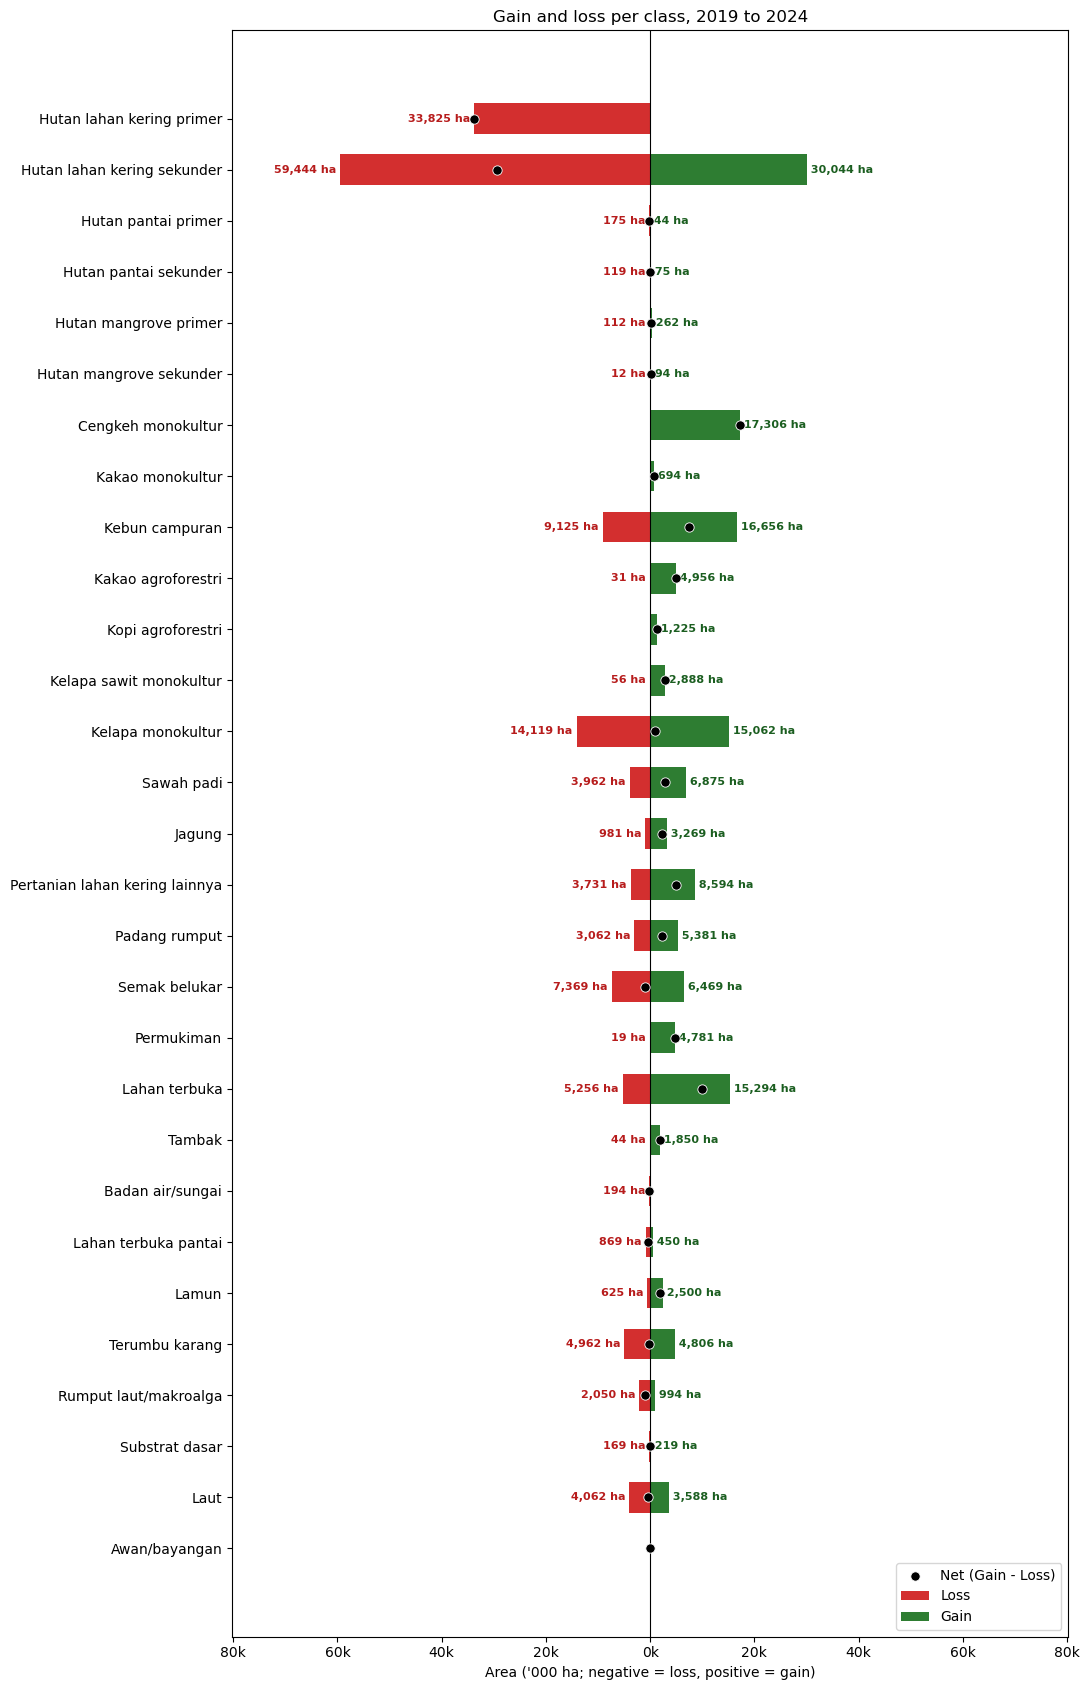

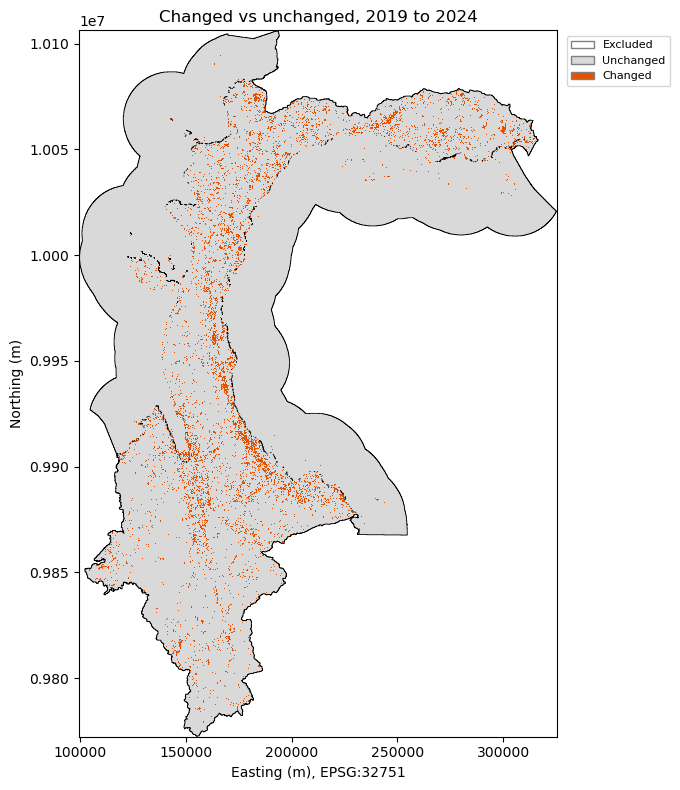

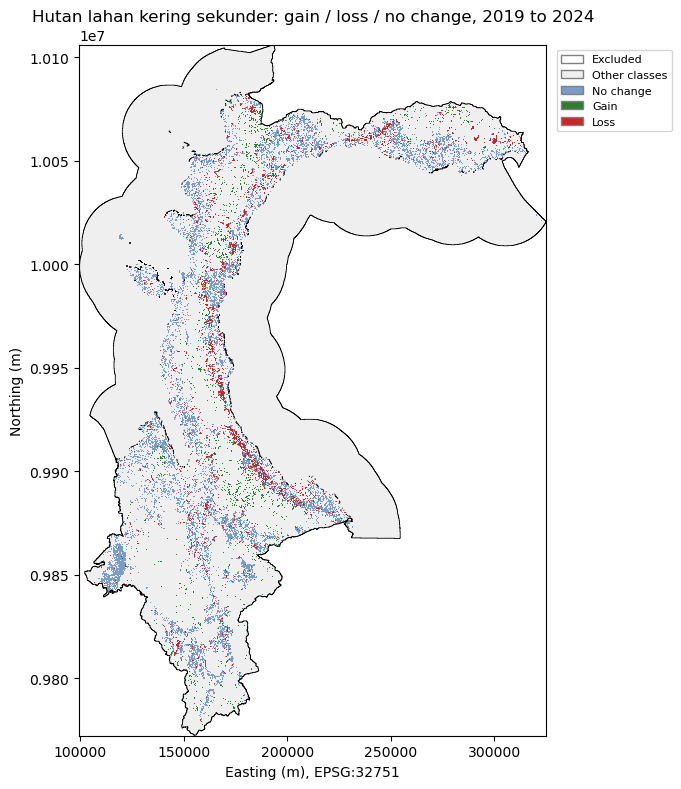

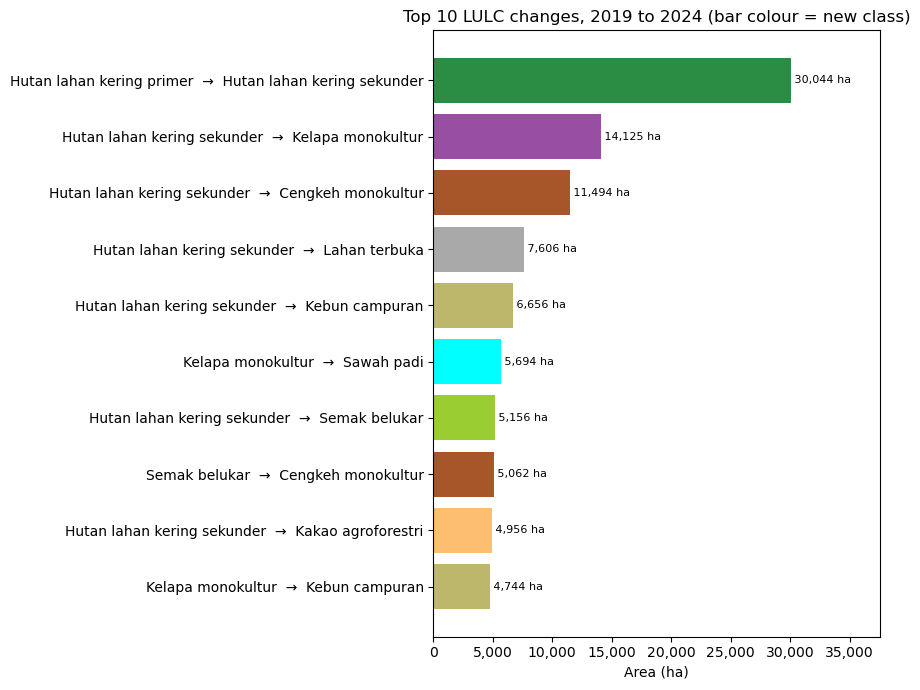

In [6]:
# Generate all figures (gain/loss, change map, class maps, top 10 changes)
figs = change.plot_all()
plt.show()


## 6. save to local

In [7]:
# Export outputs to multi-sheet Excel and PNGs
saved_path = change.save()
print(f"Saved: {saved_path}")


Saved: D:/Comparison_Analysis_Outputs\lulc_crosstab_2019_2024.xlsx
